In [49]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
import scipy.stats as stats
import sympy as sym
import matplotlib.pyplot as plt
import cvxpy as cv


In [4]:
masks = pd.read_csv("time_series_Worldwide_20031231-1800_20261010-1802.csv")


N = len(masks)
masks.head()


,Time,mask
0,2004-01-01,10
1,2004-02-01,10
2,2004-03-01,9
3,2004-04-01,9
4,2004-05-01,8


Part A

In [19]:
X = np.zeros((N,N))
t = np.arange(1,N+1)
lmbda = [1,10,100,1000]
for i in range(1,N):
    X[:,i] = np.maximum((t - i),0)
X[:,0] = 1
sym.pprint(X)

[[  1.   0.   0. ...   0.   0.   0.] 
 [  1.   1.   0. ...   0.   0.   0.] 
 [  1.   2.   1. ...   0.   0.   0.] 
                 ...                 
 [  1. 271. 270. ...   1.   0.   0.] 
 [  1. 272. 271. ...   2.   1.   0.] 
 [  1. 273. 272. ...   3.   2.   1.]]


In [38]:
D = np.ones((N))
D[0] = 0
D[1] = 0
D = np.diag(D)
sym.pprint(D)

[[0. 0. 0. ... 0. 0. 0.] 
 [0. 0. 0. ... 0. 0. 0.] 
 [0. 0. 1. ... 0. 0. 0.] 
           ...           
 [0. 0. 0. ... 1. 0. 0.] 
 [0. 0. 0. ... 0. 1. 0.] 
 [0. 0. 0. ... 0. 0. 1.]]


In [44]:
y = np.array(masks['mask'])
b = X.T @ y
fits = {}
for lam in lmbda:
    A = X.T @ X + lam*D
    beta_hat = np.linalg.solve(A,b)
    mu_hat = X @ beta_hat
    fits[lam] = mu_hat

fits

{1: array([10.09767367,  9.68849823,  9.18164913,  8.79095445,  8.54859316,
         8.69578978,  8.92517566,  9.23359238,  9.69270588, 10.14058969,
         9.72261147,  9.44354919,  9.58556935,  9.98728926,  9.90175686,
         9.59473087,  9.43021311,  9.17747456,  9.17557308,  9.58609197,
        10.39504145, 11.00233976, 10.4128637 ,  9.6291503 ,  9.24087291,
         9.20855458,  9.25184541,  8.88184095,  8.35779134,  8.05710575,
         7.99940204,  8.14719229,  8.46358655,  8.76450258,  8.40227159,
         7.96472219,  7.63741143,  7.64117415,  7.55943375,  7.33443954,
         7.34900701,  7.65151212,  7.94132386,  8.26629907,  8.73297072,
         9.18157274,  8.71936833,  8.27204793,  8.04593368,  7.9752998 ,
         7.94848678,  7.87853537,  7.7299995 ,  7.58889774,  7.81124917,
         8.16417512,  8.60354773,  8.92106406,  8.30487339,  8.02206099,
         8.03483872,  8.28335744,  8.67292931,  8.82550904,  8.69012204,
         8.39028467,  8.35939126,  8.64055147,  

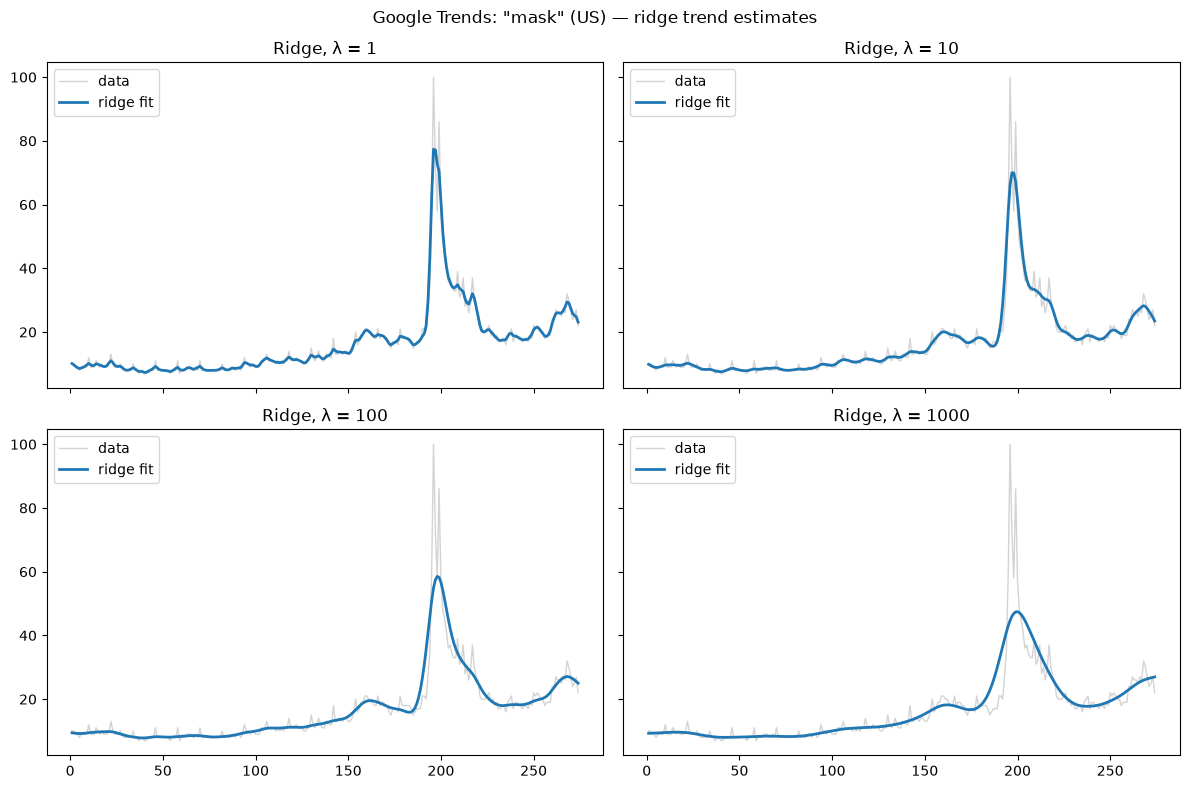

In [46]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True, sharey=True)
for ax, (lam, mu_hat) in zip(axes.flat, fits.items()):
    ax.plot(t, y, color='lightgray', lw=1, label='data')
    ax.plot(t, mu_hat, color='C0', lw=2, label='ridge fit')
    ax.set_title(f'Ridge, λ = {lam}')
    ax.legend(loc='upper left')
fig.suptitle('Google Trends: "mask" (US) — ridge trend estimates')
fig.tight_layout()
plt.show()

We see here that lamdbda of 1 is abel to capture the peaks far better than the other 3 options

Part B

In [59]:
fits_lasso = {}
lasso_betas = {}
for lam in lmbda:
    beta = cv.Variable(N)
    obj = cv.Minimize(cv.sum_squares((y-X@beta)) + lam * cv.norm1(beta))
    cv.Problem(obj).solve()
    mu_hat = X@beta.value
    fits_lasso[lam] = mu_hat
    lasso_betas[lam] = beta.value.copy()    
fits_lasso


{1: array([ 9.53929676,  9.53929676,  9.20087905,  8.86246133,  8.52404362,
         8.75652776,  8.98901191,  9.22149605,  9.73397351, 10.24645097,
         9.77312455,  9.29979814,  9.62727918,  9.95476022,  9.78528016,
         9.6158001 ,  9.44632004,  9.27683998,  9.10735992,  9.28815528,
        10.42368945, 11.55922362, 10.4578633 ,  9.35650299,  9.27504977,
         9.19359655,  9.11214333,  8.77836762,  8.4445919 ,  8.11081619,
         8.01497867,  8.24251067,  8.47004267,  8.69757467,  8.35556367,
         8.01355267,  7.67154167,  7.5823108 ,  7.49307993,  7.40384906,
         7.31461819,  7.63393756,  7.95325692,  8.27257628,  8.76121318,
         9.24985008,  8.73908666,  8.22832324,  8.1136933 ,  7.99906335,
         7.88443341,  7.76980346,  7.65517352,  7.54054358,  7.87884562,
         8.21714766,  8.68685906,  9.15657047,  8.        ,  8.04200177,
         8.2       ,  8.35799823,  8.51599646,  8.6739947 ,  8.5760053 ,
         8.47801591,  8.38002651,  8.67697746,  

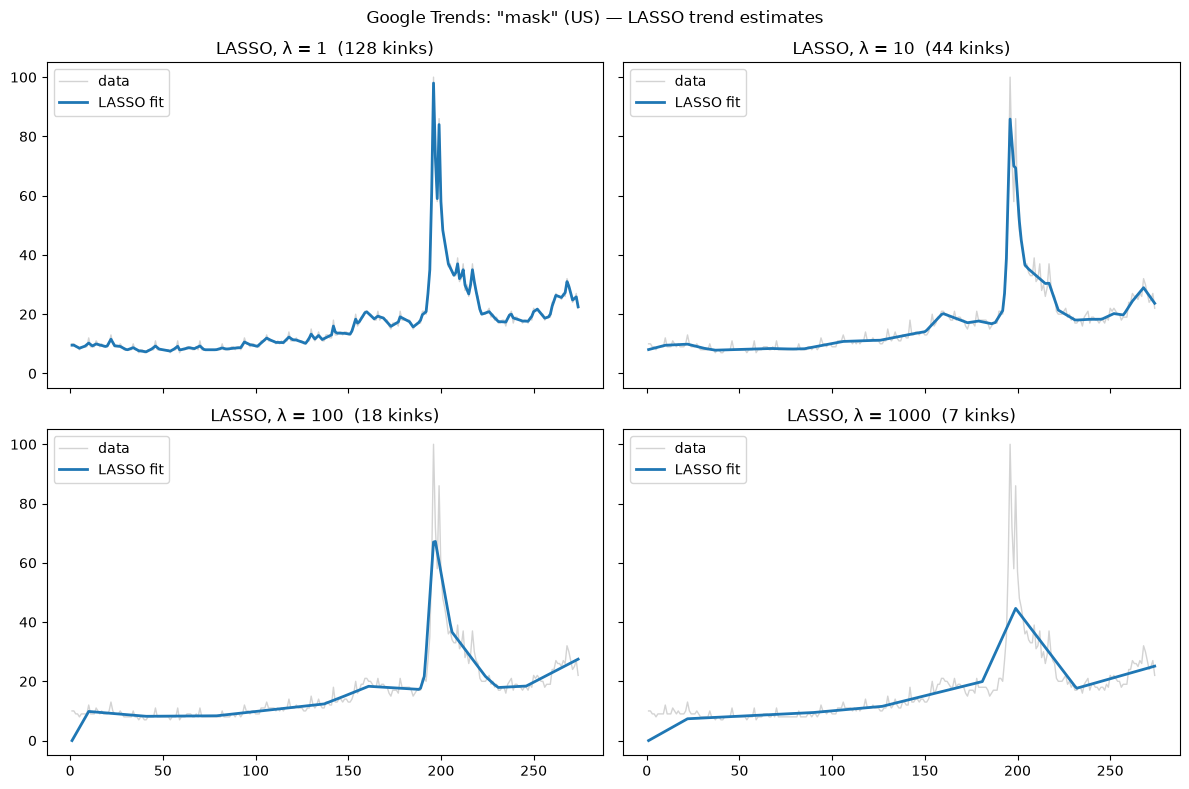

In [60]:

def plot_fits(fits, y, dates, method, betas=None):
    fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True, sharey=True)
    for ax, (lam, mu_hat) in zip(axes.flat, fits.items()):
        ax.plot(dates, y, color='lightgray', lw=1, label='data')
        ax.plot(dates, mu_hat, color='C0', lw=2, label=f'{method} fit')
        title = f'{method}, λ = {lam}'
        if betas is not None:
            kinks = np.sum(np.abs(betas[lam][2:]) > 1e-6)
            title += f'  ({kinks} kinks)'
        ax.set_title(title)
        ax.legend(loc='upper left')
    fig.suptitle(f'Google Trends: "mask" (US) — {method} trend estimates')
    fig.tight_layout()
    plt.show()

plot_fits(fits_lasso, y, t, 'LASSO', betas=lasso_betas)

Lambda 1 is able to model much of the spikes and general trend fair better than any other lambda value

Part C

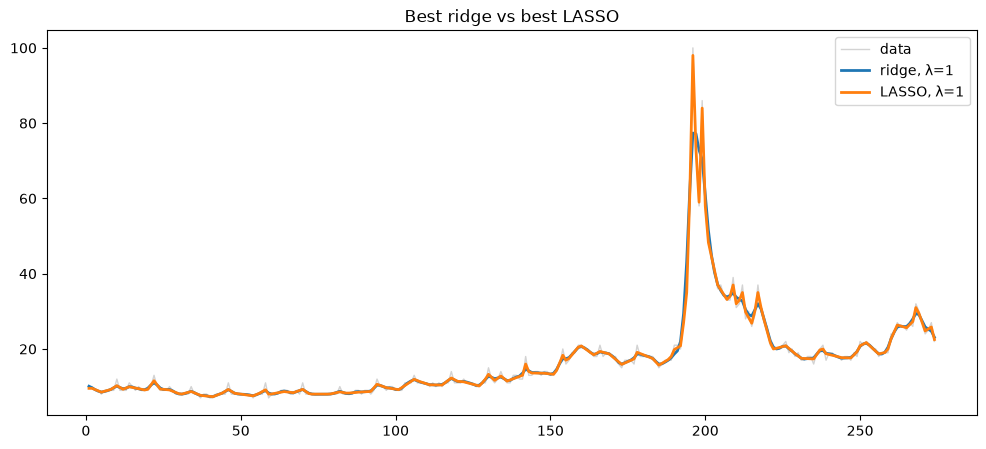

In [63]:
plt.figure(figsize=(12, 5))
plt.plot(t, y, color='lightgray', lw=1, label='data')
plt.plot(t, fits[1], lw=2, label='ridge, λ=1')
plt.plot(t, fits_lasso[1], lw=2, label='LASSO, λ=1')
plt.legend(); plt.title('Best ridge vs best LASSO')
plt.show()

Part C

Looking at the graph we an see that lasso captures the peaks far better than the ridge model. We see that both models can follow the trend fairly well but lasso can capture the peaks and jumping motion far stronger as ridge producing a smoother curve